# 01 · A picture is a table of numbers — and FER-2013

**Read first:** `01_theory/02_ml_basics.md`, `01_theory/03_images_nn.md` (§3.1–3.3), `01_theory/06_data_training.md` (§6.1–6.2)

1. a face as a 48×48 matrix
2. normalisation — and **measuring** the two magic numbers 0.5077 and 0.2550 yourself
3. histogram equalisation for bad light
4. the imbalance (436 disgust vs 7,215 happy) and the class weights
5. augmentation — only on the training set
6. the dataset is noisy: find the junk

**Data:** put FER-2013 in `13_FaceEmotion/data/fer2013/` with the same layout as your project
(`train/<emotion>/*.jpg|png`, `test/<emotion>/...`) — see your project's `data/README.md`. The folder is not in
Git (the images are not ours to redistribute).

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("../data/fer2013")
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]      # alphabetical folder order

def load_split(split):
    X, y = [], []
    for label, emotion in enumerate(EMOTIONS):
        for f in sorted((ROOT / split / emotion).iterdir()):
            X.append(cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)); y.append(label)
    return np.stack(X), np.array(y)

X_train, y_train = load_split("train")
print("train:", X_train.shape, X_train.dtype, " pixel range", X_train.min(), "-", X_train.max())

train: (28709, 48, 48) uint8  pixel range 0 - 255


## 1. A face is a matrix

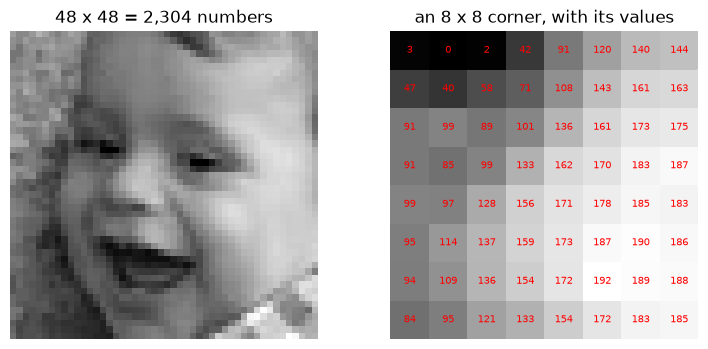

In [2]:
face = X_train[np.flatnonzero(y_train == EMOTIONS.index("happy"))[3]]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(face, cmap="gray"); axes[0].set_title("48 x 48 = 2,304 numbers")
axes[1].imshow(face[18:26, 14:22], cmap="gray")
for (r, c), v in np.ndenumerate(face[18:26, 14:22]):
    axes[1].text(c, r, v, ha="center", va="center", fontsize=7, color="red")
axes[1].set_title("an 8 x 8 corner, with its values")
for a in axes: a.axis("off")
plt.show()

## 2. Normalisation — where do 0.5077 and 0.2550 come from?

`pixel / 255` → 0..1, then `(x − mean) / std` → mean ≈ 0, std ≈ 1. The two numbers are the mean and standard
deviation of all **training** pixels. Measure them:

In [3]:
pixels = X_train.astype(np.float32) / 255.0
mean, std = pixels.mean(), pixels.std()
print(f"mean {mean:.4f}   std {std:.4f}     (your config.py: 0.5077 and 0.2550)")
z = (pixels - 0.5077) / 0.2550
print(f"after normalising: mean {z.mean():.3f}, std {z.std():.3f}")

mean 0.5077   std 0.2551     (your config.py: 0.5077 and 0.2550)


after normalising: mean 0.000, std 1.000


**Train/serve skew:** the camera frames in real time must be normalised with **these same** numbers. Normalise
differently and the network receives numbers it never saw — accuracy collapses with no error message.

## 3. Histogram equalisation — rescuing a dark face

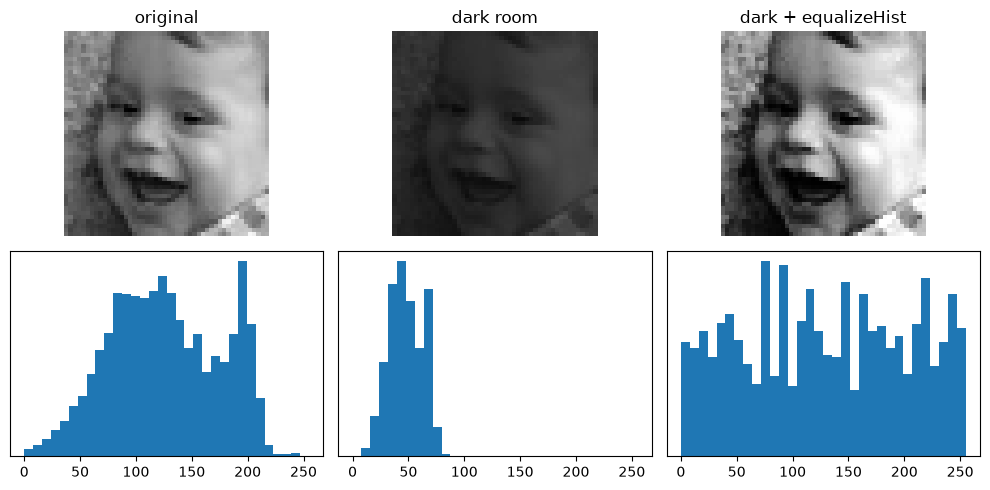

In [4]:
dark = (face.astype(np.float32) * 0.3 + 10).astype(np.uint8)        # simulate bad light
eq = cv2.equalizeHist(dark)
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for col, (img, title) in enumerate(((face, "original"), (dark, "dark room"), (eq, "dark + equalizeHist"))):
    axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, col].set_title(title); axes[0, col].axis("off")
    axes[1, col].hist(img.ravel(), bins=32, range=(0, 255)); axes[1, col].set_yticks([])
plt.tight_layout(); plt.show()

The dark face uses only a narrow band of grey values; `equalizeHist` spreads them over 0–255 again.

## 4. The imbalance and the class weights

$$ w_i = \frac{\text{total}}{K \cdot \text{count}_i} $$

In [5]:
counts = np.bincount(y_train, minlength=7)
weights = len(y_train) / (7 * counts)
for e, c, w in zip(EMOTIONS, counts, weights):
    print(f"{e:9s} {c:5d}   weight {w:5.2f}   normalised (mean 1) {w / weights.mean():5.2f}")

angry      3995   weight  1.03   normalised (mean 1)  0.48
disgust     436   weight  9.41   normalised (mean 1)  4.40
fear       4097   weight  1.00   normalised (mean 1)  0.47
happy      7215   weight  0.57   normalised (mean 1)  0.27
neutral    4965   weight  0.83   normalised (mean 1)  0.39
sad        4830   weight  0.85   normalised (mean 1)  0.40
surprise   3171   weight  1.29   normalised (mean 1)  0.60


A mistake on a *disgust* face costs ~16× more than one on a *happy* face. Without it, the network learns that
disgust "almost never happens" and never guesses it.

## 5. Augmentation — only for training

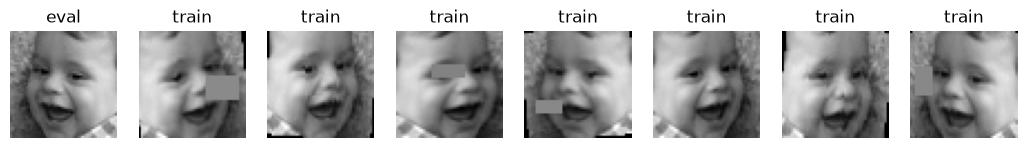

In [6]:
import torch
from torchvision import transforms

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(48, scale=(0.85, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.5077], [0.2550]),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.1)),
])
eval_tf = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), transforms.Normalize([0.5077], [0.2550])])

torch.manual_seed(0)
fig, axes = plt.subplots(1, 8, figsize=(13, 2))
axes[0].imshow(eval_tf(face)[0], cmap="gray"); axes[0].set_title("eval")
for a in axes[1:]:
    a.imshow(train_tf(face)[0], cmap="gray"); a.set_title("train")
for a in axes: a.axis("off")
plt.show()

Every epoch the network sees a slightly different face — the dataset is multiplied for free. A smile is a smile in
the mirror too, so the flip is safe. **Never** put a random transform in the evaluation pipeline: your test score
would change on every run.

## 6. The dataset is noisy

FER-2013 was collected automatically from image search. Some "faces" are blank or are not faces at all:

12 almost-uniform images (std of pixels < 5) in the training set


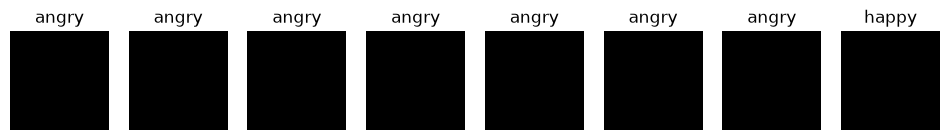

In [7]:
flat = X_train.reshape(len(X_train), -1)
blank = np.flatnonzero(flat.std(1) < 5)
print(f"{len(blank)} almost-uniform images (std of pixels < 5) in the training set")
fig, axes = plt.subplots(1, min(8, len(blank)), figsize=(12, 2))
for a, i in zip(np.atleast_1d(axes), blank[:8]):
    a.imshow(X_train[i], cmap="gray", vmin=0, vmax=255); a.set_title(EMOTIONS[y_train[i]]); a.axis("off")
plt.show()

This noise is one reason **label smoothing** helps (theory §6.3), and one reason ~65–70% is a good accuracy on this
dataset: even humans agree with the FER-2013 labels only ~65% of the time.

## ✍️ Try it yourself

1. Compute the class weights by hand for disgust and happy, and normalise so the mean is 1.
2. Add `transforms.RandomVerticalFlip()` to the training pipeline. Why is that a **bad** augmentation for faces?
3. Measure the mean and std of the **test** pixels. Should you use them for normalisation? Why not?

Then solve exercises 1–3 in `03_exercises/`.